[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IMForg-Public/imf_big_data_workshop_sti26/blob/main/notebooks/Google%20Colab%20Setup.ipynb)

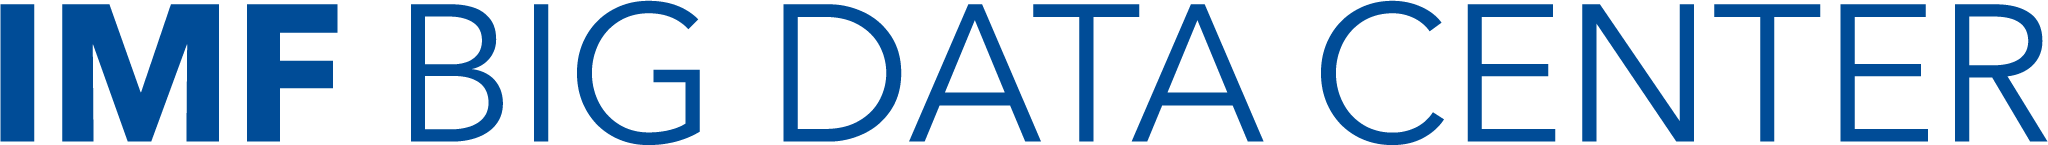


# Test Google Colab Setup



---

<br>**Contributors:** [Alessandra Sozzi](asozzi@imf.org)
<br> **Last update:** Oct-2026
<br> **Description:** This notebook checks your Google Colab setup and introduces the workflow used throughout the workshop: mounting Google Drive, setting the ROOT to the repository folder, and loading a sample data file
<br> **References:**

# Using Google Colab

**Google Colab** is a cloud-based platform for running **Jupyter notebooks**. It offers a convenient and powerful environment for data science and machine learning tasks.

### 🌟 Key Advantages

- **Free access to GPUs and TPUs:** Accelerate your code with high-performance hardware.  
- **Pre-installed libraries:** Use popular data science and machine learning packages without manual installation.  
- **Easy sharing and collaboration:** Seamlessly share notebooks with others.  
- **No setup required:** Run your code directly in your browser — no local configuration needed.

---

### 🧭 Colab Workflow for This Workshop

Throughout this workshop, we will be using **Google Colab**. You will repeatedly follow this general workflow:

1. **Mount the Google Drive**  
2. **Set the `ROOT`** to the repository folder `imf_big_data_workshop_sti26-main`  
3. **Specify the path** to the `data` folder (or one of its subfolders) containing the data files for the session  

---


## 1. **Mount the Google Drive**


**Reasoning**:
Mounting your Google Drive in Google Colab essentially creates a direct link between your Colab notebook environment and your Google Drive storage. Think of it like connecting a USB drive to your computer, but instead of a physical drive, it's your cloud-based Google Drive.

Once mounted, Colab can access the files and folders in your Drive as if they were on the local file system. This means you can:

*   **Read data files:** Load datasets (like CSV, Excel, or image files) directly from your Drive into your Colab notebook for analysis or processing.
*   **Save results:** Save the output of your code, such as generated plots, processed data, or trained models, directly back to your Drive. This ensures your work is saved and easily accessible.
*   **Organize project files:** Keep all your project-related files, including notebooks, data, and scripts, together in your Drive and access them seamlessly from Colab.

In short, mounting Google Drive provides persistent storage for your work and makes it easy to manage files for your Colab projects.

**You’ll be prompted to open a link, sign in with your Google account and give Google Colab permission to access your files.**

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2. **Set the `ROOT`** to the repository folder  

**Reasoning**:
Define the `ROOT` folder for this workshop: the `imf_big_data_workshop_sti26-main` folder you uploaded to your Google Drive.



In [2]:
ROOT = '/content/drive/MyDrive/imf_big_data_workshop_sti26-main'


## 3. **Specify the path** to the `data` folder containing the data files  


**Reasoning**:
Construct the full path to the data folder by joining the root folder and `data`. Each session's notebooks point at a subfolder of it, for example `data/cropland` or `data/text_analytics`.



In [3]:
import os

DATA_PATH = os.path.join(ROOT, 'data')

# Check if the data folder exists
if os.path.exists(DATA_PATH):
    print(f'Data path set to: {DATA_PATH}')
else:
    print(f'Error: data folder not found at {DATA_PATH}. Please ensure the repository folder is in the top level of your Google Drive.')


Data path set to: /content/drive/MyDrive/imf_big_data_workshop_sti26-main/data


# Download sample data and save it to the data folder


**Reasoning**:
Download the Iris dataset from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris) (CC BY 4.0) straight into a DataFrame. This is the pattern you will use all week: fetch data from a provider, save it under `data/`, then read it back.

Notice how you do not need to install pandas in Google Colab — it comes pre-installed. `pandas` is one of the most popular Python libraries for data analysis and manipulation.

This is again **one of the main advantages of Google Colab** — many essential libraries come pre-installed, which **greatly simplifies setup time** and allows you to focus directly on your analysis rather than on environment configuration.


In [4]:
import pandas as pd

# Iris dataset from the UCI Machine Learning Repository (Fisher, 1936), CC BY 4.0
IRIS_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

iris_df = pd.read_csv(IRIS_URL, header=None, names=columns)
print(f'Downloaded {len(iris_df)} rows from {IRIS_URL}')
display(iris_df.head())


Downloaded 150 rows from https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


**Reasoning**:
Files created inside a Colab session disappear when the session ends. Saving the CSV into the `data/setup` folder of your Drive copy keeps it, and reading it back confirms the path works.


In [5]:
# Save the data to the data/setup folder of your Drive copy, then read it back to check
SETUP_PATH = os.path.join(DATA_PATH, 'setup')
os.makedirs(SETUP_PATH, exist_ok=True)

IRIS_DATA_PATH = os.path.join(SETUP_PATH, 'iris.csv')
iris_df.to_csv(IRIS_DATA_PATH, index=False)
print(f'Saved to: {IRIS_DATA_PATH}')

iris_check = pd.read_csv(IRIS_DATA_PATH)
print(f'Read back {len(iris_check)} rows from Google Drive')
display(iris_check.tail())


Saved to: /content/drive/MyDrive/imf_big_data_workshop_sti26-main/data/setup/iris.csv
Read back 150 rows from Google Drive


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


# Great, you are done!

You have successfully mounted your Google Drive, set the path to the data folder, downloaded a dataset and saved it to your Drive. You are now ready to proceed with the workshop!
